In [1]:
import numpy as np 
import pandas as pd 
import scanpy as sc 
import lightgbm as lgb 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score 
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split
from tqdm import tqdm 
import anndata as ad 
import sys  
sys.path.append('/home/rsun@ZHANGroup.local/sly_data/gbdt_lr')
from utils import load_data, GBDT_LR


/tmp/ipykernel_3687232/2662155237.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['cluster 7', 'cluster 5', 'cluster 7', 'cluster 7', 'cluster 10', ..., 'cluster 1', 'cluster 8', 'cluster 1', 'cluster 1', 'cluster 1']
Length: 21861
Categories (11, object): ['cluster 1', 'cluster 7', 'cluster 5', 'cluster 8', ..., 'cluster 10', 'cluster 11', 'cluster 3', 'cluster 9']' has dtype incompatible with category, please explicitly cast to a compatible dtype first.
  scdata.obs.loc[:,'cluster'] = scdata.obs.leiden.map(cluster_dic)


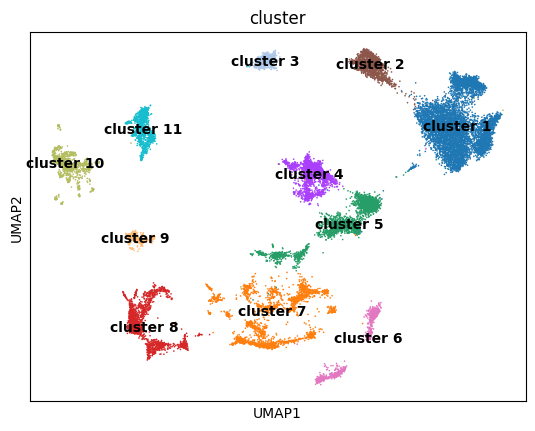

In [ ]:
import json
with open('/home/rsun@ZHANGroup.local/sly_data/sly_06_require/leiden_dic.json', 'r') as f:
    cluster_dic = json.load(f)
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/celltype_check/modify_multi.h5ad')
scdata.obs.loc[:,'cluster'] = scdata.obs.leiden.map(cluster_dic)
sc.pl.umap(scdata, color = ['cluster'], legend_loc = 'on data')

In [ ]:
gbdt_lr = GBDT_LR(scdata, label_key = 'cluster') 
gbdt_lr.split_data()

C = gbdt_lr.label_encoder.classes_.shape[0]
print(f'cluster number {C}')

# 设置LightGBM参数
gbm_params = {
    'objective': 'multiclass',  # 多分类任务
    'num_class': C,  # 类别数量
    'metric': 'multi_logloss',  # 多分类的损失函数
    'boosting_type': 'gbdt',  # 使用GBDT算法
    'num_leaves': 5,  # 叶子节点数
    'learning_rate': 0.05,  # 学习率
    'feature_fraction': 0.9,  # 特征采样比例
    'bagging_fraction': 0.8,  # 数据采样比例
    'bagging_freq': 5,  # 每5次迭代进行一次bagging
    'verbose': 0  # 不输出详细信息
    }

gbdt_lr.gbm_fit(gbm_params)

cluster number 11
Training until validation scores don't improve for 10 rounds


In [ ]:
gbdt_lr.gbm_transform()
gbdt_lr.lg_fit()

Start predicting...
Writing transformed training data


100%|██████████| 10930/10930 [00:00<00:00, 11308.13it/s]


Writing transformed testing data


100%|██████████| 10931/10931 [00:00<00:00, 11488.80it/s]
/home/rsun@ZHANGroup.local/sly_data/gbdt_lr/utils.py:177: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  testing_label = self.sc_new.obs.loc[:,self.label_key][testing_id]
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/rsun@ZHANGroup.local/sly_dat

ROC AUC Score on lg split Data: 1.0
ROC AUC Score on gbm split Data: 0.9984331748906939


## Parse the GBDT tree

In [ ]:
def parse_lightgbm_tree(tree, feature_names=None):
    """
    解析 LightGBM 树结构，生成叶节点路径条件表达式
    :param tree: 通过 model.dump_model()['tree_info'][0]['tree_structure'] 获取的树结构
    :param feature_names: 特征名称列表，若为 None 则使用 column_{index} 格式
    :return: 字典，键为叶节点索引，值为条件表达式字符串
    """
    def traverse(node, path, results):
        if 'leaf_index' in node:
            # 处理叶节点
            conditions = []
            for feat, thres, op in path:
                conditions.append(f"{feat} {op} {thres:.3f}")
            results[node['leaf_index']] = " and ".join(conditions)
        else:
            # 处理非叶节点
            feat_idx = node['split_feature']
            thres = node['threshold']
            feat_name = f"column_{feat_idx}" if feature_names is None else feature_names[feat_idx]
            
            # 左子树（<= 阈值）
            left_path = path + [(feat_name, thres, "<=")]
            traverse(node.get('left_child', {}), left_path, results)
            
            # 右子树（> 阈值）
            right_path = path + [(feat_name, thres, ">")]
            traverse(node.get('right_child', {}), right_path, results)
    
    results = {}
    traverse(tree, [], results)
    return results

In [ ]:
from tqdm import tqdm 
N = gbdt_lr.gbm_model.num_trees()
num_leaves = gbdt_lr.gbm_params['num_leaves']

feature_names = scdata.var.index.values  # 根据实际特征数量调整
res_dic = {}
for i in tqdm(range(N)):
    tree_structure = gbdt_lr.gbm_model.dump_model()['tree_info'][i]['tree_structure']
    leaf_conditions = parse_lightgbm_tree(tree_structure, feature_names)

    for key in leaf_conditions:
        res_dic[num_leaves*i + key] = leaf_conditions[key] 

new_feature_name = [f'{res_dic[i]}' for i in range(N*num_leaves)]
new_feature_name = np.array(new_feature_name )

100%|██████████| 1100/1100 [02:48<00:00,  6.52it/s]


In [7]:
feature_dict = {gene: i for i, gene in enumerate(new_feature_name)}

unique_feature = np.unique(new_feature_name) 
unique_id = []

for ele in unique_feature:
    unique_id.append(feature_dict[ele])
unique_id = np.array(unique_id)

In [8]:
sc_new = gbdt_lr.sc_new 
sc_new.var.loc[:,'var_info'] = new_feature_name
sc_new = sc_new[:,unique_id]

# sc.tl.rank_genes_groups(sc_new, groupby = 'cluster', method = 'wilcoxon')
# sc.pl.rank_genes_groups_dotplot(sc_new, groupby = 'cluster', n_genes = 4,min_logfoldchange=2,)

In [ ]:
df = sc.get.rank_genes_groups_df(sc_new, group = 'cluster 1')

for ele in df['names'][10:30]:
    print(ele, sc_new.var.loc[ele,'var_info'])

## all cluster marker gene set 

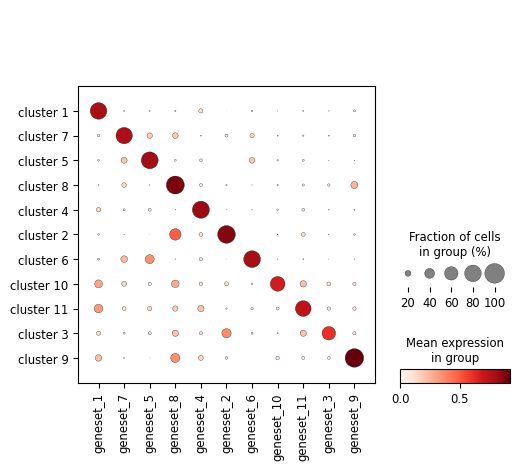

In [16]:
import matplotlib.pyplot as plt

idx_1 = scdata[:,'Pex5l'].X.toarray() == 0 
idx_2 = scdata[:,'Synpr'].X.toarray() > 0
idx_3 = scdata[:,'Otof'].X.toarray() > 0 
idx_4 = scdata[:,'Csmd1'].X.toarray() == 0
set_1 = idx_1 & (idx_2 | idx_3) & idx_4

idx_1 = scdata[:,'Csmd1'].X.toarray() > 0 
idx_2 = scdata[:,'Sox5'].X.toarray() == 0
idx_3 = scdata[:,'Synpr'].X.toarray() > 0
set_2  = idx_1 & idx_2 & idx_3

set_3 = scdata[:,'Mag'].X.toarray() > 0


idx_1  = scdata[:,'Trhde'].X.toarray() > 0
idx_2 = scdata[:,'Epha3'].X.toarray() == 0 
idx_3 = scdata[:,'Satb2'].X.toarray() == 0
set_4 = idx_1 & idx_2 & idx_3

idx_1 = scdata[:,'Pex5l'].X.toarray() > 5
idx_2 = scdata[:,'Erc2'].X.toarray() == 0
set_5 = idx_1 & idx_2

idx_1 = scdata[:,'Kctd16'].X.toarray() == 0
idx_2 = scdata[:,'Grin2b'].X.toarray() == 0
set_6 = idx_1 & idx_2

idx_1 = scdata[:,'Satb2'].X.toarray() > 0
idx_2 = scdata[:,'Bcl11b'].X.toarray() == 0
set_7 = idx_1 & idx_2

idx_1 = scdata[:,'Nrg3'].X.toarray() > 6
idx_2 = scdata[:,'Kcnh7'].X.toarray() > 2
idx_3 = scdata[:,'Nav3'].X.toarray() > 4
set_8 = idx_1  & idx_2 & idx_3

idx_1 = scdata[:,'Nrg3'].X.toarray() > 6
idx_2 = scdata[:,'Nectin3'].X.toarray() > 2
set_9 = idx_1  & idx_2 

set_10 = scdata[:,'Dock8'].X.toarray() > 0
set_11 = scdata[:,'Slc1a3'].X.toarray() > 0 


data = [set_1, set_2, set_3, set_4, set_5, set_6, set_7, set_8, set_9, set_10, set_11]
data = np.array(data, dtype = np.int16).reshape(11,-1).T

import anndata as ad 
sc_dis = ad.AnnData(data, obs = scdata.obs,)
sc_dis.obsm['X_umap'] = scdata.obsm['X_umap'].copy()
sc_dis.var.index = [f'geneset_{i}' for i in range(1,12)]
ax = sc.pl.dotplot(sc_dis, var_names = [f'geneset_{i}' for i in [1,7,5,8,4,2,6,10,11,3,9]], groupby = 'cluster', 
                   categories_order=[f'cluster {i}' for i in [1,7,5,8,4,2,6,10,11,3,9]], show = False)
plt.savefig('dotplot.pdf', bbox_inches = 'tight')